In [135]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import (StackingClassifier,RandomForestClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,confusion_matrix,classification_report,balanced_accuracy_score)
from sklearn.pipeline import make_pipeline

In [136]:
df0 = pd.read_csv("ACTG175.csv")
print("df shp:", df0.shape)
display(df0.head())

df shp: (2139, 27)


,pidnum,age,wtkg,hemo,homo,drugs,karnof,oprior,z30,zprior,...,offtrt,cd40,cd420,cd496,r,cd80,cd820,cens,days,arms
0,10056,48,89.8128,0,0,0,100,0,0,1,...,0,422,477,660.0,1,566,324,0,948,2
1,10059,61,49.4424,0,0,0,90,0,1,1,...,0,162,218,NaN,0,392,564,1,1002,3
2,10089,45,88.4520,0,1,1,90,0,1,1,...,1,326,274,122.0,1,2063,1893,0,961,3
3,10093,47,85.2768,0,1,0,100,0,1,1,...,0,287,394,NaN,0,1590,966,0,1166,3
4,10124,43,66.6792,0,1,0,100,0,1,1,...,0,504,353,660.0,1,870,782,0,1090,0


In [137]:
print("cols:")
print(df0.columns.tolist())
print("\ndf info:")
df0.info()
print("\nstats:")
display(df0.describe(include="all").T)

cols:
['pidnum', 'age', 'wtkg', 'hemo', 'homo', 'drugs', 'karnof', 'oprior', 'z30', 'zprior', 'preanti', 'race', 'gender', 'str2', 'strat', 'symptom', 'treat', 'offtrt', 'cd40', 'cd420', 'cd496', 'r', 'cd80', 'cd820', 'cens', 'days', 'arms']

df info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2139 entries, 0 to 2138
Data columns (total 27 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   pidnum   2139 non-null   int64  
 1   age      2139 non-null   int64  
 2   wtkg     2139 non-null   float64
 3   hemo     2139 non-null   int64  
 4   homo     2139 non-null   int64  
 5   drugs    2139 non-null   int64  
 6   karnof   2139 non-null   int64  
 7   oprior   2139 non-null   int64  
 8   z30      2139 non-null   int64  
 9   zprior   2139 non-null   int64  
 10  preanti  2139 non-null   int64  
 11  race     2139 non-null   int64  
 12  gender   2139 non-null   int64  
 13  str2     2139 non-null   int64  
 14  strat    2139 non-null   int

,count,mean,std,min,25%,50%,75%,max
pidnum,2139.0,248778.252454,234237.289399,10056.0,81446.5000,190566.0000,280277.0000,990077.00000
age,2139.0,35.248247,8.709026,12.0,29.0000,34.0000,40.0000,70.00000
wtkg,2139.0,75.125311,13.263164,31.0,66.6792,74.3904,82.5552,159.93936
hemo,2139.0,0.084151,0.277680,0.0,0.0000,0.0000,0.0000,1.00000
homo,2139.0,0.661057,0.473461,0.0,0.0000,1.0000,1.0000,1.00000
drugs,2139.0,0.131370,0.337883,0.0,0.0000,0.0000,0.0000,1.00000
karnof,2139.0,95.446470,5.900985,70.0,90.0000,100.0000,100.0000,100.00000
oprior,2139.0,0.021973,0.146629,0.0,0.0000,0.0000,0.0000,1.00000
z30,2139.0,0.550257,0.497584,0.0,0.0000,1.0000,1.0000,1.00000
zprior,2139.0,1.000000,0.000000,1.0,1.0000,1.0000,1.0000,1.00000


In [138]:
print("dup rows:", df0.duplicated().sum())
df1 = df0.drop_duplicates().copy()
print("shp after:", df1.shape)

dup rows: 0
shp after: (2139, 27)


In [139]:
ms = pd.DataFrame({"miss n": df1.isnull().sum(),"miss %": (df1.isnull().mean() * 100).round(2)})
display(ms[ms["miss n"] > 0].sort_values("miss n", ascending=False))

,miss n,miss %
cd496,797,37.26


In [140]:
kcol = [c for c in ["pidnum", "days", "cens", "arms", "treat","cd40", "cd80", "cd420", "cd496", "cd820"]if c in df1.columns]
display(df1[kcol].head(10))
for c in kcol:
    print(f"\n{c} — uniq vals:")
    print(df1[c].value_counts(dropna=False).head(15))

,pidnum,days,cens,arms,treat,cd40,cd80,cd420,cd496,cd820
0,10056,948,0,2,1,422,566,477,660.0,324
1,10059,1002,1,3,1,162,392,218,NaN,564
2,10089,961,0,3,1,326,2063,274,122.0,1893
3,10093,1166,0,3,1,287,1590,394,NaN,966
4,10124,1090,0,0,0,504,870,353,660.0,782
5,10140,1181,0,1,1,235,860,339,264.0,1060
6,10165,794,1,0,0,244,708,225,106.0,699
7,10190,957,0,0,0,401,889,366,453.0,720
8,10198,198,1,3,1,214,652,107,8.0,131
9,10229,188,1,0,0,221,221,132,NaN,759



pidnum — uniq vals:
pidnum
10056    1
10059    1
10089    1
10093    1
10124    1
10140    1
10165    1
10190    1
10198    1
10229    1
10241    1
10341    1
10343    1
10361    1
10364    1
Name: count, dtype: int64

days — uniq vals:
days
1087    34
1088    24
1154    18
1089    16
1091    16
1090    16
993     15
1132    14
1097    13
1117    13
1139    12
1014    12
1140    12
1133    11
990     11
Name: count, dtype: int64

cens — uniq vals:
cens
0    1618
1     521
Name: count, dtype: int64

arms — uniq vals:
arms
3    561
0    532
2    524
1    522
Name: count, dtype: int64

treat — uniq vals:
treat
1    1607
0     532
Name: count, dtype: int64

cd40 — uniq vals:
cd40
300    27
280    24
420    23
320    19
410    19
380    19
230    18
400    18
350    17
270    16
440    16
390    16
310    15
290    15
360    14
Name: count, dtype: int64

cd80 — uniq vals:
cd80
1040    10
870     10
620     10
950      9
1000     9
880      9
990      9
520      8
770      8
570      8
680 

In [141]:
hz = 365
df1 = df1.dropna(subset=["days", "cens"]).copy()
df1 = df1[df1["days"] >= 0].copy()
df1["event"] = (df1["cens"] == 0).astype(int) #cens-1 is censored only
vld = (((df1["event"] == 1) & (df1["days"] <= hz))| (df1["days"] >= hz))# The 365-day outcome is known if an event was observed by day 365
dm = df1.loc[vld].copy()
dm["target"] = (dm["days"] > hz).astype(int)# 0 = event occurred on or before day 365,1 = event-free through day 365
print("rows after clean:", len(df1))
print("rows w/ known 365d outcome:", len(dm))
print("\ntgt counts (0=event by day 365, 1=event-free through day 365):")
print(dm["target"].value_counts().sort_index())
print("\ntgt props:")
print(dm["target"].value_counts(normalize=True).sort_index().round(4))
if dm["target"].nunique() != 2:
    raise ValueError("target contains fewer than two classes; verify target construction.")

rows after clean: 2139
rows w/ known 365d outcome: 2016

tgt counts (0=event by day 365, 1=event-free through day 365):
target
0      81
1    1935
Name: count, dtype: int64

tgt props:
target
0    0.0402
1    0.9598
Name: proportion, dtype: float64


In [142]:
exc = ["pidnum","days","cens","event","target","cd420","cd496","cd820","offtrt","r"]
if "treat" in dm.columns:
    exc.append("arms")
elif "arms" in dm.columns:
    exc.append("treat")
fc = [c for c in dm.columns if c not in exc]
xx = dm[fc].copy()
yy = dm["target"].copy()
print("sel feats:")
print(fc)
print("\nfeat shp:", xx.shape)
print("tgt shp:", yy.shape)

sel feats:
['age', 'wtkg', 'hemo', 'homo', 'drugs', 'karnof', 'oprior', 'z30', 'zprior', 'preanti', 'race', 'gender', 'str2', 'strat', 'symptom', 'treat', 'cd40', 'cd80']

feat shp: (2016, 18)
tgt shp: (2016,)


In [143]:
xtr0, xte0, ytr, yte = (train_test_split(xx,yy,test_size=0.20,random_state=42,stratify=yy))
print("xtr:", xtr0.shape)
print("xte:", xte0.shape)
print("ytr:", ytr.shape)
print("yte:", yte.shape)

xtr: (1612, 18)
xte: (404, 18)
ytr: (1612,)
yte: (404,)


In [144]:
xtr1 = pd.get_dummies(xtr0,drop_first=True,dtype=int)
xte1 = pd.get_dummies(xte0,drop_first=True,dtype=int)
xte1 = xte1.reindex(columns=xtr1.columns,fill_value=0)
print("enc xtr shp:", xtr1.shape)
print("enc xte shp:", xte1.shape)

enc xtr shp: (1612, 18)
enc xte shp: (404, 18)


In [145]:
imp = SimpleImputer(strategy="median")
xtr = pd.DataFrame(imp.fit_transform(xtr1),columns=xtr1.columns,index=xtr1.index)
xte = pd.DataFrame(imp.transform(xte1),columns=xte1.columns,index=xte1.index)
print("miss vals xtr:", xtr.isnull().sum().sum())
print("miss vals xte:", xte.isnull().sum().sum())
display(xtr.head())

miss vals xtr: 0
miss vals xte: 0


,age,wtkg,hemo,homo,drugs,karnof,oprior,z30,zprior,preanti,race,gender,str2,strat,symptom,treat,cd40,cd80
155,30.0,69.10000,0.0,1.0,0.0,100.0,0.0,1.0,1.0,444.0,0.0,1.0,1.0,3.0,0.0,1.0,218.0,914.0
1585,36.0,69.40080,0.0,1.0,0.0,100.0,0.0,1.0,1.0,1155.0,0.0,1.0,1.0,3.0,0.0,1.0,186.0,1135.0
1853,33.0,43.00128,0.0,0.0,0.0,90.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,181.0,367.0
850,32.0,85.80000,0.0,1.0,0.0,80.0,0.0,1.0,1.0,1116.0,0.0,1.0,1.0,3.0,0.0,1.0,270.0,740.0
1636,33.0,56.92680,0.0,1.0,0.0,90.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,329.0,419.0


In [146]:
print("xtr feat shp:", xtr.shape)
print("xte feat shp:", xte.shape)
print("\nytr dist:")
print(ytr.value_counts())
print("\nyte dist:")
print(yte.value_counts())
assert xtr.columns.equals(xte.columns)
assert xtr.isnull().sum().sum() == 0
assert xte.isnull().sum().sum() == 0
print("\nprep checks passed.")

xtr feat shp: (1612, 18)
xte feat shp: (404, 18)

ytr dist:
target
1    1547
0      65
Name: count, dtype: int64

yte dist:
target
1    388
0     16
Name: count, dtype: int64

prep checks passed.


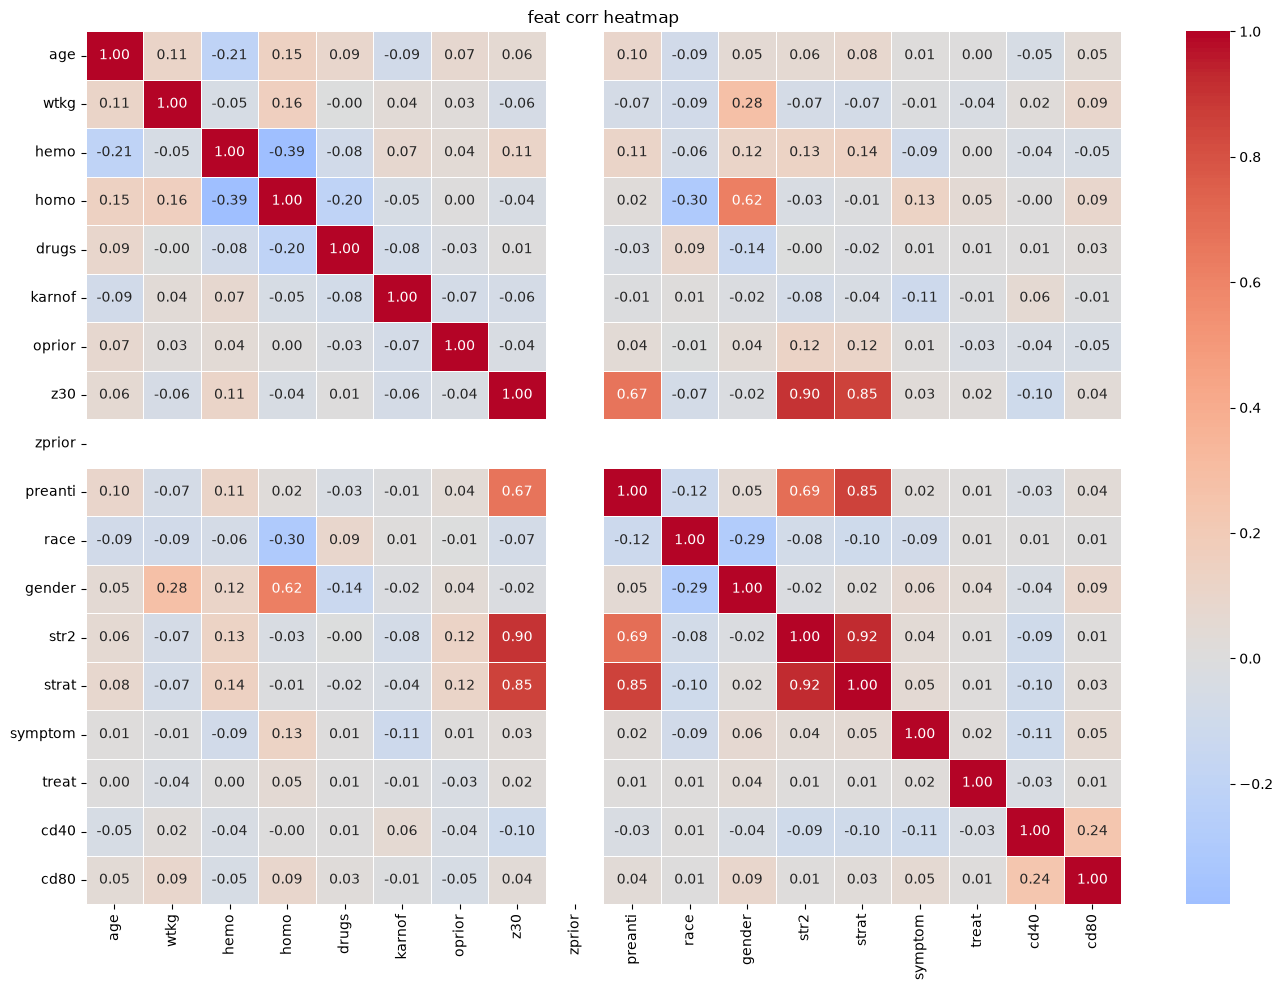

In [147]:
cr = xtr.corr()
plt.figure(figsize=(14, 10))
sns.heatmap(cr,annot=True,cmap="coolwarm",center=0,fmt=".2f",linewidths=0.5)
plt.title("feat corr heatmap")
plt.tight_layout()
plt.show()

In [148]:
ucr = cr.where(np.triu(np.ones(cr.shape),k=1).astype(bool))
hcr = (ucr.stack().reset_index())
hcr.columns = ["feature 1","feature 2","correlation"]
hcr = hcr[hcr["correlation"].abs() >= 0.80].sort_values("correlation",key=abs,ascending=False)
print("feat pairs w/ |corr| >= 0.80:")
display(hcr)

feat pairs w/ |corr| >= 0.80:


,feature 1,feature 2,correlation
121,str2,strat,0.918590
94,z30,str2,0.899734
95,z30,strat,0.850956
103,preanti,strat,0.848203


In [149]:
bst = [("lr",make_pipeline(StandardScaler(),LogisticRegression(max_iter=5000,class_weight="balanced",random_state=42))),
    ("dt",DecisionTreeClassifier(max_depth=5,class_weight="balanced",random_state=42)),
    ("rf",RandomForestClassifier( n_estimators=100,class_weight="balanced",random_state=42,n_jobs=-1))]

fins = {"log reg": make_pipeline(StandardScaler(),LogisticRegression(max_iter=5000,class_weight="balanced",random_state=42)),
    "dec tree": DecisionTreeClassifier(max_depth=5,class_weight="balanced",random_state=42)}

r1 = []
m1 = {}

for nm, fm in fins.items():
    stk = StackingClassifier(estimators=bst,final_estimator=fm,cv=5,stack_method="predict_proba",n_jobs=-1)
    stk.fit(xtr, ytr)
    prd = stk.predict(xte)
    prb = stk.predict_proba(xte)[:, 1]
    m1[nm] = stk
    r1.append({
        "final est": nm,
        "acc": accuracy_score(yte, prd),
        "bal acc": balanced_accuracy_score(yte, prd),
        "c0 prec": precision_score(yte, prd, pos_label=0, zero_division=0),
        "c0 rec": recall_score(yte, prd, pos_label=0, zero_division=0),
        "c0 f1": f1_score(yte, prd, pos_label=0, zero_division=0),
        "c1 f1": f1_score(yte, prd, pos_label=1, zero_division=0),
        "roc auc": roc_auc_score(yte, prb)
    })

r1 = pd.DataFrame(r1).sort_values("c0 f1", ascending=False).reset_index(drop=True)
display(r1.round(4))

,final est,acc,bal acc,c0 prec,c0 rec,c0 f1,c1 f1,roc auc
0,log reg,0.6238,0.6543,0.0696,0.6875,0.1264,0.7603,0.7007
1,dec tree,0.5223,0.5715,0.0508,0.6250,0.0939,0.6756,0.6121


In [150]:
bnm = r1.sort_values("c0 f1", ascending=False).iloc[0]["final est"]
bstk = m1[bnm]
bprd = bstk.predict(xte)
bprb = bstk.predict_proba(xte)[:, 1]
print("sel final est:", bnm)
print("\nclass report:")
print(classification_report(yte,bprd,labels=[0, 1],target_names=["event by day 365", "event-free through day 365"],zero_division=0))
print("conf mat:")
print(confusion_matrix(yte, bprd, labels=[0, 1]))
print("bal acc:", round(balanced_accuracy_score(yte, bprd), 4))
print("roc auc:", round(roc_auc_score(yte, bprb), 4))

sel final est: log reg

class report:
                            precision    recall  f1-score   support

          event by day 365       0.07      0.69      0.13        16
event-free through day 365       0.98      0.62      0.76       388

                  accuracy                           0.62       404
                 macro avg       0.52      0.65      0.44       404
              weighted avg       0.94      0.62      0.74       404

conf mat:
[[ 11   5]
 [147 241]]
bal acc: 0.6543
roc auc: 0.7007


In [151]:
sc = StandardScaler()
xtrs = sc.fit_transform(xtr)
xtes = sc.transform(xte)
print("scaled xtr shp:", xtrs.shape)
print("scaled xte shp:", xtes.shape)

scaled xtr shp: (1612, 18)
scaled xte shp: (404, 18)


In [152]:
pc = PCA(n_components=0.99)
xtrp = pc.fit_transform(xtrs)
xtep = pc.transform(xtes)
print("orig feat n:", xtr.shape[1])
print("pca comp n:", xtrp.shape[1])
print("tot exp var:",pc.explained_variance_ratio_.sum())

orig feat n: 18
pca comp n: 15
tot exp var: 0.9916906906384311


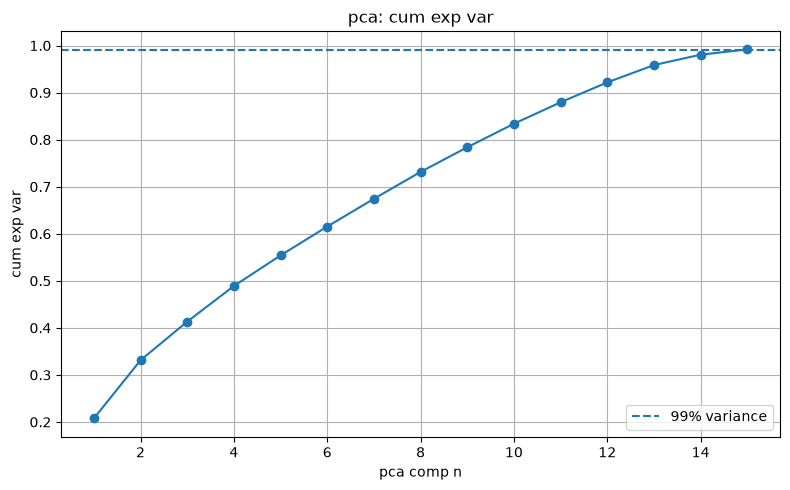

In [153]:
cv = np.cumsum(pc.explained_variance_ratio_)
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cv) + 1),cv,marker="o")
plt.axhline(y=0.99,linestyle="--",label="99% variance")
plt.xlabel("pca comp n")
plt.ylabel("cum exp var")
plt.title("pca: cum exp var")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [154]:
mds = {"log reg": make_pipeline(StandardScaler(),LogisticRegression(max_iter=5000,class_weight="balanced",random_state=42)),
    "dec tree": DecisionTreeClassifier(max_depth=5,class_weight="balanced",random_state=42),
    "rand forest": RandomForestClassifier(n_estimators=100,class_weight="balanced",random_state=42,n_jobs=-1)}
r3 = []
for nm, md in mds.items():
    md.fit(xtr, ytr)
    pro = md.predict(xte)
    pbo = md.predict_proba(xte)[:, 1]
    r3.append({"mdl": nm,"feat set": "orig","acc": accuracy_score(yte, pro),"bal acc": balanced_accuracy_score(yte, pro),"c0 rec": recall_score(yte, pro, pos_label=0, zero_division=0),"c0 f1": f1_score(yte, pro, pos_label=0, zero_division=0),"c1 f1": f1_score(yte, pro, pos_label=1, zero_division=0),"roc auc": roc_auc_score(yte, pbo)})
    # PCA features
    md.fit(xtrp, ytr)
    prp = md.predict(xtep)
    pbp = md.predict_proba(xtep)[:, 1]
    r3.append({"mdl": nm,"feat set": "pca","acc": accuracy_score(yte, prp),"bal acc": balanced_accuracy_score(yte, prp),"c0 rec": recall_score(yte, prp, pos_label=0, zero_division=0),"c0 f1": f1_score(yte, prp, pos_label=0, zero_division=0),"c1 f1": f1_score(yte, prp, pos_label=1, zero_division=0),"roc auc": roc_auc_score(yte, pbp)})
r3 = pd.DataFrame(r3)
display(r3.sort_values(["mdl", "feat set"]).round(4))

,mdl,feat set,acc,bal acc,c0 rec,c0 f1,c1 f1,roc auc
2,dec tree,orig,0.6460,0.5461,0.4375,0.0892,0.7803,0.5768
3,dec tree,pca,0.6733,0.5902,0.5000,0.1081,0.8000,0.6517
0,log reg,orig,0.6287,0.6269,0.6250,0.1176,0.7649,0.6901
1,log reg,pca,0.6312,0.6282,0.6250,0.1183,0.7668,0.6809
4,rand forest,orig,0.9579,0.4987,0.0000,0.0000,0.9785,0.6728
5,rand forest,pca,0.9579,0.4987,0.0000,0.0000,0.9785,0.6263


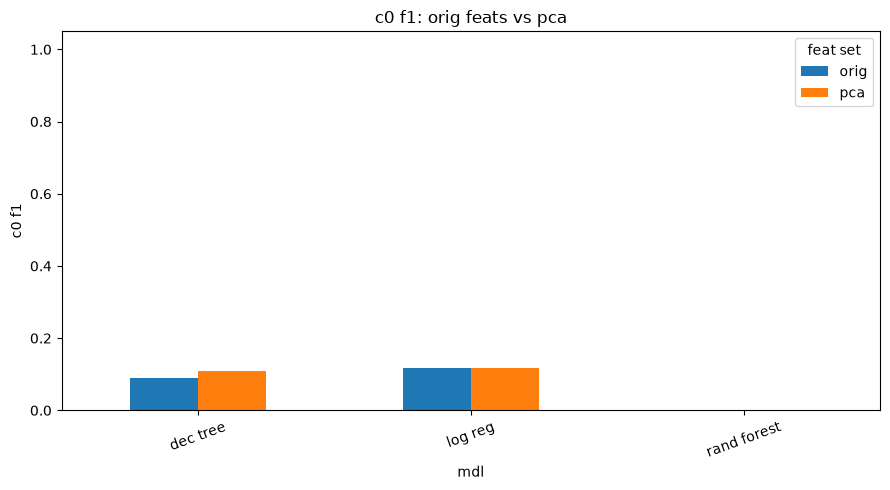

In [155]:
p3 = r3.pivot(index="mdl",columns="feat set",values="c0 f1")[["orig", "pca"]]
p3.plot(kind="bar", figsize=(9, 5))
plt.title("c0 f1: orig feats vs pca")
plt.ylabel("c0 f1")
plt.xlabel("mdl")
plt.xticks(rotation=20)
plt.ylim(0, 1.05)
plt.legend(title="feat set")
plt.tight_layout()
plt.show()